# Diagnóstico por semilla: PCA + media frente a POD

Análisis posterior y exploratorio de la confirmación 2111–2120. No se entrenan redes, no se cambian hiperparámetros y no se selecciona un nuevo ganador. Diferencias negativas favorecen PCA + media.

| Semilla | Diferencia RMSE | Rango medio | Coincidencia QR media |
|---:|---:|---:|---:|
| 2111 | -0.00103 | 5.62 | 0.107 |
| 2112 | -0.06455 | 5.48 | 0.126 |
| 2113 | +0.02437 | 5.50 | 0.145 |
| 2114 | +0.00089 | 5.53 | 0.131 |
| 2115 | +0.00779 | 5.62 | 0.181 |
| 2116 | +0.00143 | 5.51 | 0.132 |
| 2117 | -0.01769 | 5.48 | 0.133 |
| 2118 | -0.05545 | 5.54 | 0.108 |
| 2119 | +0.06690 | 5.31 | 0.109 |
| 2120 | +0.03816 | 5.49 | 0.124 |

## Qué queda controlado

El rango y el complemento Sobol coinciden exactamente en cada actualización. Por ello no explican una diferencia de presupuesto entre métodos. El rango puede variar entre semillas, pero su asociación con el resultado es descriptiva. Se analiza solo el subconjunto QR al comparar ubicaciones: incluir los puntos Sobol compartidos inflaría artificialmente la coincidencia. Las regiones |x| < 0.1 y t > 0.5 son descriptores geométricos elegidos después de ver la cohorte, no una demostración de dónde está el error.

Coincidencia QR promedio: 0.130. Distancia simétrica media al vecino más cercano: 0.05588, con x y t normalizados por sus longitudes de dominio. Coincidencia exacta baja no implica regiones alejadas. El histograma usa una rejilla 16×16 y pocos puntos QR: su variación total es sensible a los bordes y a la escasez de puntos. En las historias guardadas, la media aporta en promedio 0.944 de la energía residual y POD captura 1.000000 de la energía de esa media. POD sin centrar también puede representar una media persistente; añadirla explícitamente no garantiza una ventaja.

**Diagnóstico**

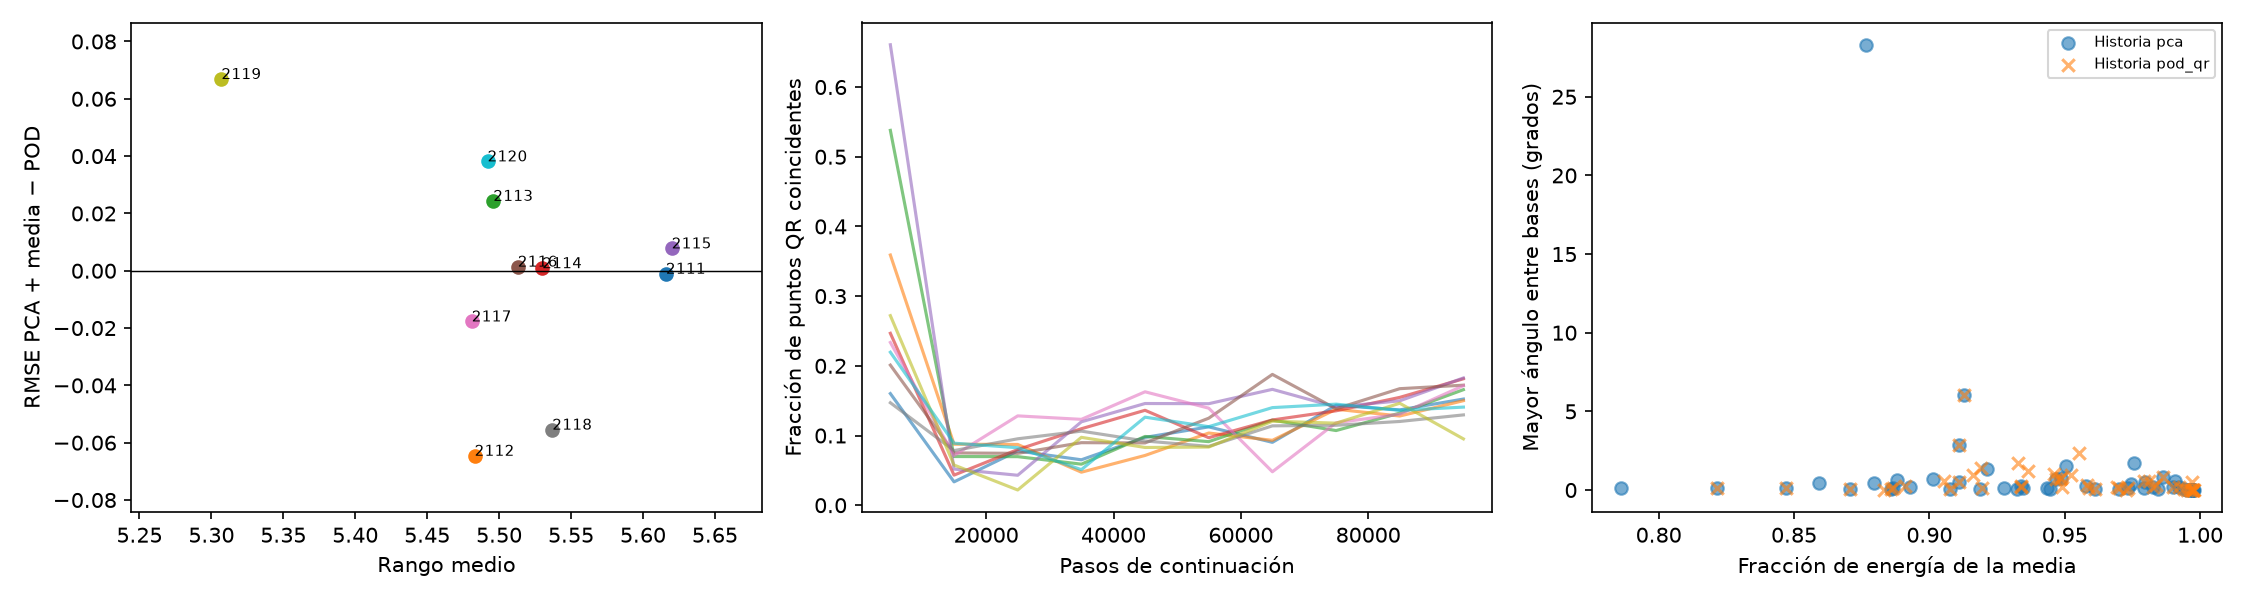

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/pair_confirmation/pca_mean_vs_pod_confirmation_10new_100k_v1/diagnostics/diagnostic_overview.png'), format='png', embed=True))


## Comparación sobre la misma historia

Para cada matriz guardada se reconstruyen las dos bases con igual dimensión y se mide la energía bruta, fluctuaciones y media capturadas, además del mayor ángulo entre subespacios. En historias de PCA se reconstruye su regla adaptativa real; en historias de POD se compara una PCA + media de dimensión fija igual al rango usado. Esta última es una comparación geométrica, no una trayectoria alternativa entrenada. Se verifican los puntos QR reales reconstruidos de cada método.

Las matrices completas solo están guardadas en pasos totales 100, 200, 1100, 5100 y 10000 (hasta 9900 de continuación). Las conclusiones sobre energía y subespacios se limitan a ese tramo. Los rangos, puntos y diagnósticos POD sí cubren todo el entrenamiento. No hay estados de red guardados para reconstruir mapas de error terminal; los gráficos de puntos no permiten atribuirles causalmente el error final.

**Casos extremos**

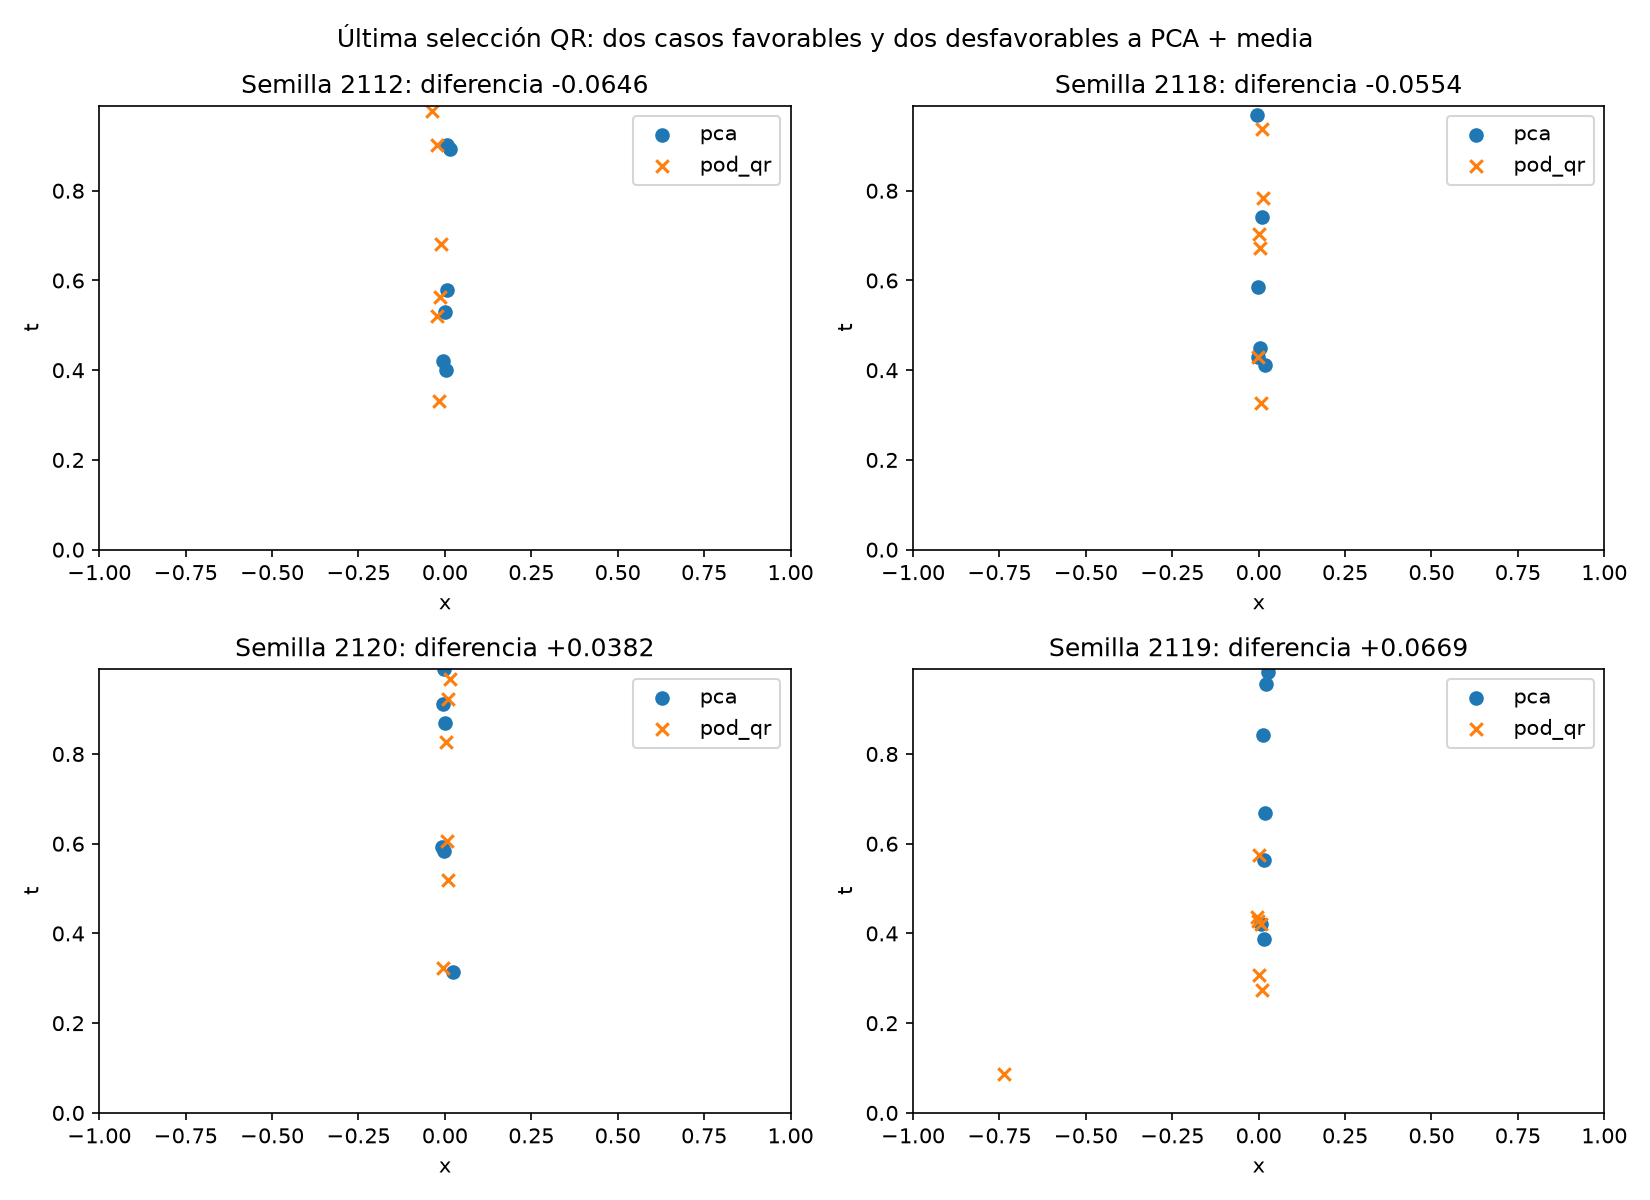

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/pair_confirmation/pca_mean_vs_pod_confirmation_10new_100k_v1/diagnostics/extreme_seed_points.png'), format='png', embed=True))


Los cuatro casos se eligieron retrospectivamente como los dos mejores y los dos peores contrastes: no son una muestra representativa ni un criterio de selección. La última selección ocurrió a 99900 pasos de continuación y se utilizó en el último intervalo.

## Archivos y siguiente control

seed_summary.csv resume las diez semillas; selection_diagnostics.csv conserva todas las actualizaciones; same_history_basis_comparison.csv contiene las comparaciones geométricas. exploratory_correlations.json guarda correlaciones de Spearman con solo diez observaciones: son hipótesis, sin inferencia confirmatoria ni interpretación causal.

Antes de cambiar el selector conviene instrumentar una próxima prueba con historias tardías y estados de red en presupuestos prefijados, para comparar la representación de la media y el error espacial cerca del resultado terminal. No se inicia esa prueba aquí. Estas semillas ya examinadas no pueden presentarse como una confirmación nueva de futuras decisiones.

Reproducir únicamente el análisis: `python scripts/diagnose_collocation_pair_confirmation.py`.